# 08. Kualitas penyalinan dan training

AI-013, TRAIN-015, 13 Oktober2026. Notebook membaca hasil eksperimen nyata dan menampilkan tahap proses. Snapshot fase development sebelum evaluasi final, dengan status lanjut di README. Sel default tidak memulai training atau membuka final targets. Data sintetis berbeda dari12anotasi reviewed. Notebook01sampai07 tetap sebagai riwayat.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
read = lambda path: json.loads((ROOT/path).read_text(encoding='utf-8'))
print('Active project interpreter:',sys.executable)

Active project interpreter: F:\Generative_AI\Vibe_Coding_Proyek_1\.venv\Scripts\python.exe


## 1. Diagnosis sebelum perubahan

Compare raw development failures and train-only lexical exposure. The old name16x last checkpoint did not improve exact generation.

In [2]:
diagnosis = read('reports/training/AI-013_COPY_DIAGNOSTIC.json')
rows = []
for checkpoint in diagnosis['development']:
    for failure in checkpoint['failures']:
        rows.append({'checkpoint_step':checkpoint['checkpoint_step'], 'recipe':failure['recipe'],
                     'name':failure['expected_name'], 'schema_valid':failure['schema_valid'],
                     'expected_first_piece':failure['expected_token'], 'actual_first_piece':failure['actual_token']})
display(pd.DataFrame(rows))
display(diagnosis['development'][0]['failures'][0]['name_piece_train_exposure'])

,checkpoint_step,recipe,name,schema_valid,expected_first_piece,actual_first_piece
0,0,pricing,Kursus Workstaralasa,True,sta,ra
1,0,testimonial,Kursus Workstaralasa,True,sta,ra
2,0,testimonial,Kursus Workstaralasa,True,sta,alad
3,0,pricing_contact,Kursus Workstaralasa,True,sta,ra
4,3600,pricing,Kursus Workstaralasa,True,sta,ra
5,3600,testimonial,Kursus Workstaralasa,False,sta,ra
6,3600,testimonial,Kursus Workstaralasa,True,sta,ra
7,3600,pricing_contact,Kursus Workstaralasa,True,sta,ra


[{'id': 48, 'piece': 'K', 'occurrences': 4740, 'train_rows': 4740},
 {'id': 372, 'piece': 'ur', 'occurrences': 1932, 'train_rows': 1932},
 {'id': 6210, 'piece': 'sus', 'occurrences': 960, 'train_rows': 960},
 {'id': 3579, 'piece': ' Work', 'occurrences': 168, 'train_rows': 168},
 {'id': 776, 'piece': 'sta', 'occurrences': 2, 'train_rows': 2},
 {'id': 303, 'piece': 'ra', 'occurrences': 210, 'train_rows': 204},
 {'id': 271, 'piece': 'la', 'occurrences': 918, 'train_rows': 894},
 {'id': 88, 'piece': 's', 'occurrences': 1284, 'train_rows': 1248},
 {'id': 70, 'piece': 'a', 'occurrences': 8142, 'train_rows': 7326}]

Exposure sesudah penambahan data juga dihitung pada train. Target development yang sama digunakan hanya untuk diagnosis, tidak dimasukkan ke train.

In [3]:
post_data = read('reports/training/AI-013_COPY_POST_DATA_DIAGNOSTIC.json')
before = pd.DataFrame(diagnosis['development'][0]['failures'][0]['name_piece_train_exposure'])
after = pd.DataFrame(post_data['development'][0]['failures'][0]['name_piece_train_exposure'])
display(before[['id','piece','train_rows']].merge(after[['id','train_rows']],on='id',suffixes=('_before','_after')))

,id,piece,train_rows_before,train_rows_after
0,48,K,4740,13358
1,372,ur,1932,5500
2,6210,sus,960,2720
3,3579,Work,168,648
4,776,sta,2,34
5,303,ra,204,774
6,271,la,894,2858
7,88,s,1248,3726
8,70,a,7326,17696


## 2. Data revision and rejected contexts

Only train data expanded. Validation/test/final are byte-identical. Counts and skipped variants are disclosed, not presented as complete vocabulary coverage.

In [4]:
summary = read('reports/training/TRAIN-015_copy_experiment.json')
data = read('reports/data/SYNTHETIC_CURRICULUM_V6.json')
display(pd.DataFrame(data['counts']).T)
display({k:summary[k] for k in ('added_train_rows','attempted_rare_pieces','pieces_with_targeted_rows','skipped_title_variants','heldout_byte_hashes_preserved','final_evaluated')})
exposure = pd.DataFrame(data['lexical_copy_augmentation']['rows_per_piece'])
display(exposure.sort_values('after',ascending=False).head(10))
display(exposure.groupby('added_targeted_rows').size().rename('piece_count').to_frame())

,rows,families
train,40158,16239
validation,1440,240
test,1440,240


{'added_train_rows': 21090,
 'attempted_rare_pieces': 3903,
 'pieces_with_targeted_rows': 1327,
 'skipped_title_variants': 20679,
 'heldout_byte_hashes_preserved': True,
 'final_evaluated': False}

,token_id,piece,before,after,added_targeted_rows
1436,2823,do,42,346,16
2125,4215,Pa,54,322,10
3005,6160,Ma,60,304,10
2008,3987,So,60,292,12
3818,7962,No,12,260,14
2358,4739,To,48,248,14
2753,5586,Do,60,246,12
742,1492,ati,60,182,16
53,328,ite,60,154,16
23,89,t,30,138,16


,piece_count
added_targeted_rows,
0,2576
2,7
4,1
10,2
12,4
14,2
16,1311


## 3. GPU probe before training

Probe weights discarded. Dataset hash and VRAM headroom recorded. Nvidia-smi totals include desktop memory.

In [5]:
display(read('reports/training/GPU-PERF-005.json'))

{'case': 'v6_packed_b48_a1',
 'batch_size': 48,
 'accumulation': 1,
 'attention_backend': 'sdpa',
 'fused_adamw': True,
 'supervised_only_logits': True,
 'allocator_config': 'expandable_segments:True',
 'precision': 'bf16',
 'context': 1024,
 'status': 'completed',
 'kind': 'discarded performance probe on train only, not quality evaluation',
 'warmup_updates': 6,
 'measured_updates': 40,
 'dataset_dir': 'data\\processed\\curriculum\\v6',
 'dataset_manifest_sha256': '0fb20da53b4e498cbcbadb7aa6296685a319ae323f68cc96e36f1659ba20d08c',
 'seconds': 7.332465100043919,
 'seconds_per_update': 0.18331162750109797,
 'target_tokens_per_second': 104470.05059668294,
 'input_tokens_per_second': 268133.5639753981,
 'examples_per_second': 261.8491835697247,
 'peak_allocated_bytes': 7057359360,
 'peak_reserved_bytes': 7184842752,
 'free_vram_bytes': 4331667456,
 'max_grad_norm': 0.32353508472442627,
 'last_loss': 0.05244540129998238,
 'update_seconds': [0.18223360000411049,
  0.18055220000678673,
  0.1

## 4. Configuration, ancestry and actual training

New continuation starts a new optimizer and schedule; it is not an exact optimizer resume.

In [6]:
training = read('reports/training/TRAIN-015.json')
display(training['config'])
display({k:training[k] for k in ('status','global_step','wall_seconds','total_train_tokens','initial_validation','final_validation','best_checkpoint','best_checkpoint_sha256','final_checkpoint_sha256')})

{'mode': 'sft',
 'data_origin': 'synthetic_curriculum',
 'human_reviewed': False,
 'curriculum_continuation': True,
 'dataset_dir': 'data/processed/curriculum/v6',
 'seed': 42,
 'block_size': 1024,
 'tokenizer': 'data/tokenizer/tokenizer.json',
 'model_config_path': 'configs/model.json',
 'device': 'cuda',
 'precision': 'bf16',
 'batch_size': 48,
 'gradient_accumulation': 1,
 'max_steps': 2400,
 'warmup_steps': 120,
 'learning_rate': 5e-05,
 'min_learning_rate': 5e-06,
 'betas': [0.9, 0.95],
 'weight_decay': 0.1,
 'grad_clip': 1.0,
 'validation_interval': 400,
 'validation_batches': 30,
 'checkpoint_interval': 400,
 'log_interval': 200,
 'reserve_free_bytes': 16106127360,
 'performance': {'attention_backend': 'sdpa',
  'fused_adamw': True,
  'pin_memory': True,
  'tf32': True,
  'supervised_only_logits': True,
  'allocator_config': 'expandable_segments:True',
  'gpu_telemetry': True,
  'selected_by': 'reports/training/GPU-PERF-004.json',
  'confirmed_on_v6_by': 'reports/training/GPU-PE

{'status': 'completed',
 'global_step': 2400,
 'wall_seconds': 481.4357408999931,
 'total_train_tokens': 46345118,
 'initial_validation': {'loss': 0.005657631831054099,
  'perplexity': 1.0056736664550927,
  'valid_tokens': 623706,
  'batches': 30},
 'final_validation': {'loss': 0.0012606918653733105,
  'perplexity': 1.0012614868714138,
  'valid_tokens': 623706,
  'batches': 30},
 'best_checkpoint': {'path': 'checkpoints\\TRAIN-015\\.versions\\best-5c95708798e442cf85e162f050b2edb0.pt',
  'payload': '.versions\\best-5c95708798e442cf85e162f050b2edb0.pt',
  'sha256': '3399709ffe2fa7981c9d26b8ff5723f7821bd78e302bea6dfe63aaf1d27c8638',
  'global_step': 2400,
  'validation_loss': 0.0012606918653733105},
 'best_checkpoint_sha256': '3399709ffe2fa7981c9d26b8ff5723f7821bd78e302bea6dfe63aaf1d27c8638',
 'final_checkpoint_sha256': '07ca1d7cbe4fe41501a230126e86ede9af94609bed4c135e525ad8518233ae1d'}

## 5. Learning curve and development generation

Generation exactness and token CE measure different aspects. No repaired JSON or substituted ground truth.

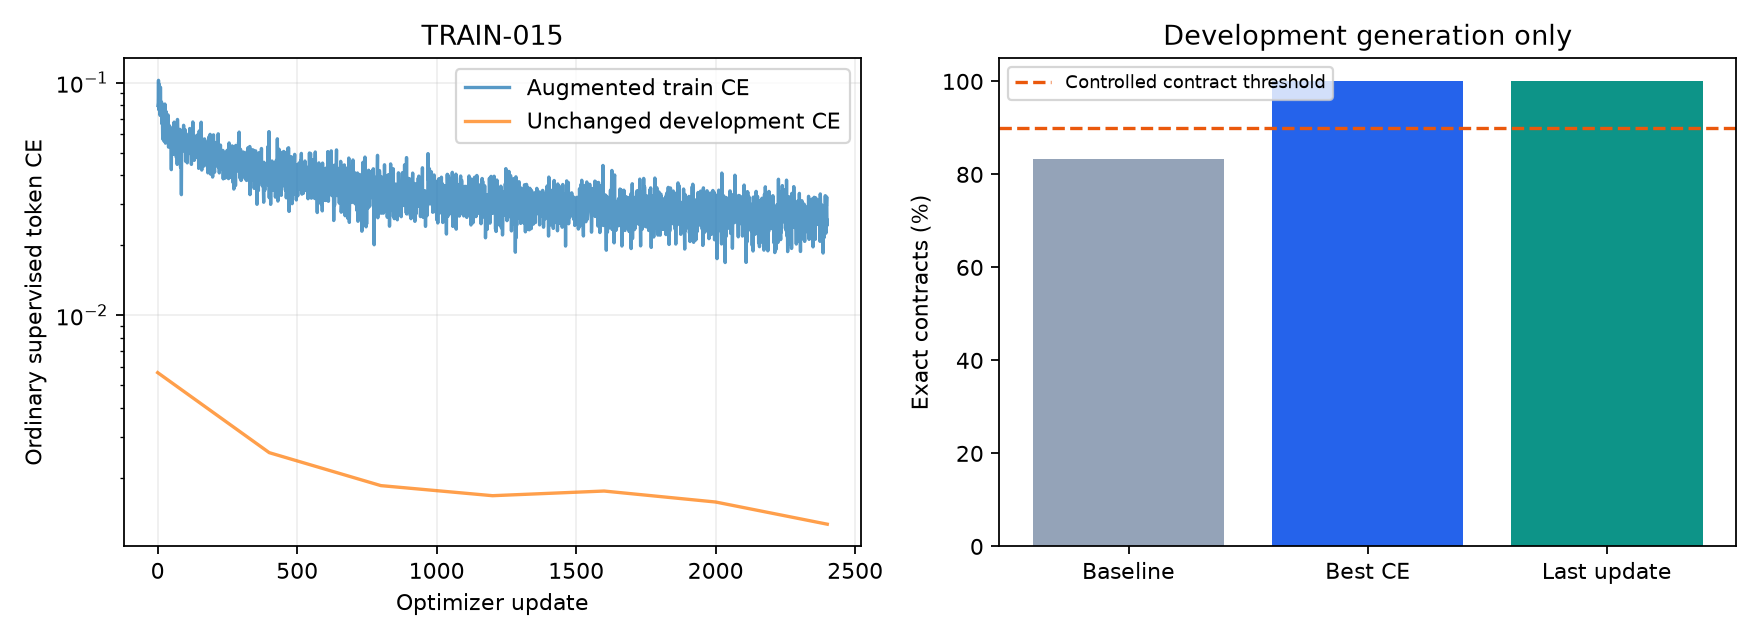

,checkpoint,step,schema,exact,count,CE,EOS
0,baseline,0,24,20,24,0.005659,True
1,best,2400,24,24,24,0.001259,True
2,last,2400,24,24,24,0.001259,True


In [7]:
display(Image(filename=str(ROOT/'reports/training/TRAIN-015_copy_training.png')))
comparison = [('baseline',summary['baseline_development']), *summary['development'].items()]
display(pd.DataFrame([{'checkpoint':name,'step':e['checkpoint_step'],'schema':e['schema_valid'],
    'exact':e['exact_contract'],'count':e['count'],'CE':e['token_metrics']['loss'],'EOS':e['all_ended_eos']} for name,e in comparison]))

## 6. Raw model output audit on development

Read actual raw prediction records, with unchanged expected development contracts for comparison. No final examples read.

In [8]:
best = summary['development']['best']
raw = read(best['outputs_path'])
display(pd.DataFrame([{'recipe':r['recipe'],'style':r['target_spec']['style_mode'],
    'expected_name':r['target_spec']['title'],'actual_name':(r['parsed_spec'] or {}).get('title'),
    'exact':r['exact_contract'],'stop':r['stop_reason']} for r in raw]))
print('One unchanged raw model output:')
print(raw[0]['raw_output'])

,recipe,style,expected_name,actual_name,exact,stop
0,profile,plain_css,Klinik Gido,Klinik Gido,True,eos
1,profile,tailwind,Studio Smartka,Studio Smartka,True,eos
2,features,plain_css,Bengkel Tibowa,Bengkel Tibowa,True,eos
3,features,tailwind,Studio Mahanigreen,Studio Mahanigreen,True,eos
4,article,plain_css,Klinik Gido,Klinik Gido,True,eos
5,article,tailwind,Kursus Starpata,Kursus Starpata,True,eos
6,pricing,plain_css,Kursus Workstaralasa,Kursus Workstaralasa,True,eos
7,pricing,tailwind,Studio Mahanigreen,Studio Mahanigreen,True,eos
8,testimonial,plain_css,Kursus Workstaralasa,Kursus Workstaralasa,True,eos
9,testimonial,tailwind,Kursus Workstaralasa,Kursus Workstaralasa,True,eos


One unchanged raw model output:
{"interactions":[{"target_id":"nav","type":"menu_toggle"}],"language":"id","schema_version":"1.0","style_mode":"plain_css","theme":{"background":"#ffffff","font":"mono","primary":"#f59e0b","text":"#111827"},"sections":[{"id":"nav","props":{"brand":"Klinik Gido","links":[{"href":"#main","label":"Beranda"}]},"type":"navbar"},{"id":"main","props":{"heading":"Klinik Gido","layout":"centered","text":"Kami mendukung usaha kecil untuk menemukan solusi praktis."},"type":"hero"},{"id":"footer","props":{"text":"Klinik Gido"},"type":"footer"}],"title":"Klinik Gido"}


## 7. Telemetry and readiness limits

Update-only samples differ from all-phase telemetry. Development results are not final or browser proof. Runtime remains TRAIN-012 until separately supported by final evidence.

In [9]:
display(summary['active_telemetry'])
display({k:summary[k] for k in ('target_tokens_per_second','active_sample_count','peak_allocated_bytes','peak_reserved_bytes','free_disk_bytes','final_evaluated')})
display(summary['limits'])

{'utilization_pct': {'mean': 92.02611940298507, 'max': 100.0},
 'temperature_c': {'mean': 63.365671641791046, 'max': 68.0},
 'power_w': {'mean': 193.38189054726368, 'max': 202.28},
 'memory_used_mib': {'mean': 10406.951492537313, 'max': 10977.0}}

{'target_tokens_per_second': 101568.8558862803,
 'active_sample_count': 804,
 'peak_allocated_bytes': 7166819328,
 'peak_reserved_bytes': 8046772224,
 'free_disk_bytes': 19039686656,
 'final_evaluated': False}

['Data are synthetic and share recipes across splits; title families are held out',
 'Data, learning rate and update budget differ from TRAIN-014; no isolated causal attribution to augmentation',
 'Development generation has been used for iteration and is not final proof',
 'Many BPE pieces cannot be reproduced under the lowercase contextual brand generator; skipped variants disclosed',
 'No JSON repair, target substitution, external pretrained weights or browser/production acceptance',
 'Runtime remains TRAIN-012 until independent final evidence supports a new selection']

## Reproduce as separate logged runs

Run `qa.prepare_copy_curriculum` only for a new immutable destination. Training: `qa.train_configured_gpu --config configs/training_copy_contexts.json --initialize-from checkpoints/TRAIN-012/best.pt`. Evaluation: `qa.evaluate_curriculum --checkpoint checkpoints/TRAIN-NNN/best.pt --split validation --report-id NEW-ID`. Wrap every execution with `qa.run_logged`. Use a new report ID; old outputs are never overwritten. Final evaluation requires an independent predeclared decision.